# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**:
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Tangaran, Grisby Paul James
- _Student No._: 2024-02777
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Initial spin configurations](12-initial-runs.png)

**Figure 1. Initial spin configurations.** Random $20\times20$ lattices for the four runs. Red is spin $+1$ (up) and blue is spin $-1$ (down).

- **What is the expected initial magnetization?** Zero. Each spin is randomly $+1$ or $-1$ with equal chance, so on average half point up and half point down, and they cancel out. A finite lattice will not be exactly zero, only close to it. The four lattices in Figure 1 have $m=-0.035$, $+0.055$, $0.000$, and $+0.045$, which are all close to zero, as expected.

- **What is the energy of a completely aligned lattice when $J>0$?** $H=-2JN^2=-800$ for $N=20$ and $J=1$. With periodic boundaries every spin has four neighbors, which gives $2N^2=800$ neighboring pairs when each pair is counted once. In an aligned lattice every pair contributes $-J$. This is the lowest possible energy, and it is the same whether all spins are up or all are down. The energy function in the code also gives $-800$ for an aligned lattice, which matches.

![Spin configurations after 10,000 sweeps](12-spins.png)

**Figure 2. Spin configurations after 10,000 sweeps** at $T=1.0$, below $T_C$ (left), and $T=3.5$, above $T_C$ (right). Below $T_C$ all the spins line up; above $T_C$ they stay mixed.

![Magnetization and energy without an external field](12-mE.png)

**Figure 3. Magnetization per spin and total energy versus Monte Carlo sweeps with $B=0$**, for the four runs at $T=1.0$ (top) and $T=3.5$ (bottom). Each run is $10^6$ attempted spin flips (2,500 sweeps), enough for every run to settle.

- **Does the system develop spontaneous magnetization?** Yes, below $T_C$. At $T=1.0$ all four runs start near $m\approx0$ and end at $m\approx\pm0.999$ even though no field is applied, and the energy drops to about $-799$, almost the aligned value of $-800$. The lattice after 10,000 sweeps in Figure 2 is also fully aligned. This is expected because at low temperature aligned neighbors have lower energy, and flips that raise the energy are rarely accepted. Above $T_C$ it does not: at $T=3.5$, $m$ keeps fluctuating around zero.

- **Why can separate simulations produce positive or negative magnetization?** Without a field, the energy depends only on whether neighboring spins are aligned, not on which way they point. All spins up and all spins down have the same energy, so neither is preferred. Each run ends up in one of them at random: runs 1 and 4 went to $m\approx-1$, and runs 2 and 3 went to $m\approx+1$. This is expected because the runs used different random initial lattices and different random flips.

- **What determines the preferred spin orientation?** Without a field, nothing in the model prefers a direction, so it is random. It depends on the initial lattice and the sequence of random spin flips, which decide which group of aligned spins grows and takes over the lattice. The starting magnetization alone does not decide it: run 4 started slightly positive ($m=+0.045$) but ended at $m\approx-1$. With a field, the field decides the direction (Figure 4).

![Magnetization and energy with an external field](12-mE-B.png)

**Figure 4. Same as Figure 3 with an external field $B=0.5$.**

- **How does the external magnetic field affect spin alignment?** The field makes the spins line up with it. At $T=1.0$ every run goes to $m=+1.000$, even runs 1 and 4, which went to $-1$ without the field. The energy settles near $-1000$, the energy of a lattice fully aligned with the field, and the runs settle much faster than without the field. At $T=3.5$ the spins only partly align ($m\approx0.60$) instead of staying around zero.

- **Why does the system favor one magnetization direction over the other?** The field term $-B\sum S_{i,j}$ lowers the energy of spins pointing along the field and raises it for spins pointing against it. Up and down are no longer equal: all spins up has $H=-1000$, while all spins down has $H=-600$. Lower energy is more likely, so flips toward $+1$ are accepted more often than flips away from it, and every run ends with positive $m$.

- **Above $T_C$ (Section 5):** Sections 2 to 4 were repeated at $T=3.5$. At this temperature, flips that raise the energy are accepted much more often, so random flips keep breaking up any alignment. The lattice stays mixed after 10,000 sweeps (Figure 2), $m$ fluctuates around zero with no field (Figure 3), and the energy stays near $-263$ instead of $-800$. With the field, the spins only partly align, with $m\approx0.60$ and $H\approx-532$ (Figure 4). This is expected because $T=3.5$ is above $T_C\approx2.269$.


### Report discussion

The results match what is expected for the 2D Ising model. The initial lattices are random, with $m$ close to zero, and a completely aligned lattice has the lowest energy, $H=-800$.

At $T=1.0$ (below $T_C$) with no field, all four runs end with almost every spin aligned: two at $m\approx+0.999$ and two at $m\approx-0.999$, with $H\approx-799$. This is spontaneous magnetization, and the mixed signs are expected because up and down have the same energy, so the direction is random.

At $T=3.5$ (above $T_C\approx2.269$) the spins stay disordered: $m$ fluctuates around zero and $H\approx-263$, because the temperature keeps breaking up any alignment.

With the field $B=0.5$, every run ends with positive $m$, as expected since spins along the field have lower energy. At $T=1.0$ all runs reach $m=+1.000$ and $H\approx-1000$; at $T=3.5$ the alignment is only partial, with $m\approx+0.60$ and $H\approx-532$.

### Other comments
- none

---
## Section 2: Code

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

# 1. Setting Up the Ising Model



Initial lattice: H = 40
Aligned lattice: H = -800


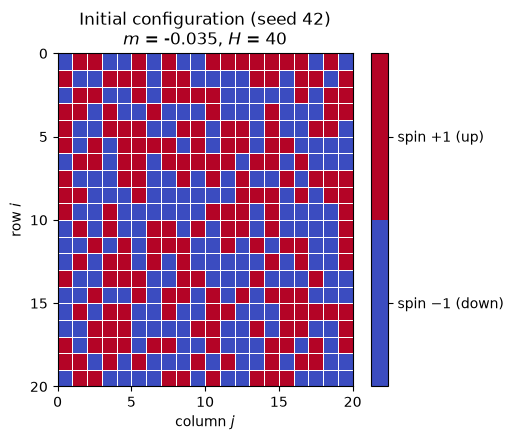

In [3]:
# Parameters
N = 20
J = 1.0
T = 1.0
T_high = 3.5
Tc = 2.269
kb = 1.0
seed = 42
seeds = [42, 67, 99, 50]
B = 0.0
B_field = 0.5
sweeps = 10000
sweeps_mE = 2500    # sweeps for Sections 3-5 (2500 x 400 = 10^6 attempted flips)


def lattice(N, seed):
    # N x N lattice of random spins, +1 or -1 with equal probability
    rng = np.random.default_rng(seed)
    return rng.choice(np.array([-1, 1]), size=(N, N))

def ising_ham(S, J, B):
    # total energy H = -J*(sum over neighbor pairs) - B*(sum of spins)
    # pairing each spin with its lower and right neighbor counts every bond exactly once, np.roll wraps the lattice around itself
    down = np.roll(S, -1, axis=0)     # S_{i+1,j}
    right = np.roll(S, -1, axis=1)    # S_{i,j+1}
    return -J*np.sum(S*(down + right)) - B*np.sum(S)

def magnetization(S):
    # magnetization per spin m = M/N^2: -1 (all spins down) to +1 (all spins up)
    return np.sum(S)/(N**2)

def plot_spins(S, title, fname=None):
    # spin map: red = +1 (up), blue = -1 (down)
    # S and title can also be lists, to draw several maps side by side; saved only if `fname` is given
    if np.ndim(S) == 2:                               # a single lattice: wrap it in a list
        S, title = [S], [title]
    plt.figure(figsize=(5.2*len(S), 4.5))
    for k in range(len(S)):
        plt.subplot(1, len(S), k + 1)
        plt.pcolormesh(S[k], cmap=plt.get_cmap("coolwarm", 2), vmin=-1, vmax=1, edgecolors="white", linewidth=0.5)
        plt.gca().invert_yaxis()                      # row 0 at the top
        plt.xticks(np.arange(0, N + 1, 5))            # whole-number ticks
        plt.yticks(np.arange(0, N + 1, 5))
        cbar = plt.colorbar(ticks=[-0.5, 0.5])
        cbar.ax.set_yticklabels(["spin $-1$ (down)", "spin $+1$ (up)"])
        plt.title(title[k])
        plt.xlabel("column $j$")
        plt.ylabel("row $i$")
    plt.tight_layout()
    if fname is not None:
        plt.savefig(fname, dpi=150)
    plt.show()

S0 = lattice(N, seed)
H0 = ising_ham(S0, J, B)
print(f"Initial lattice: H = {H0:.0f}")
print(f"Aligned lattice: H = {ising_ham(np.ones((N, N)), J, B):.0f}")

plot_spins(S0, f"Initial configuration (seed {seed})\n$m$ = {magnetization(S0):+.3f}, $H$ = {H0:.0f}")

# 2. Implementing the Metropolis Algorithm


`metropolis_fast()` is the same algorithm as `metropolis_alg()`, which is at the bottom,  written more efficiently. Flipping one spin only changes its bonds with its four neighbors, so it uses the local energy change $\Delta H=2S_{i,j}[J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B]$ instead of summing the whole lattice again, and it updates $H$ and $M$ after each accepted flip. With the same seed it follows the same sequence of flips as `metropolis_alg()` and ends at the same $m$ and $H$, so it is the version used for the longer runs in Sections 3 to 5.

T = 1.0: final m = -1.000, final H = -800


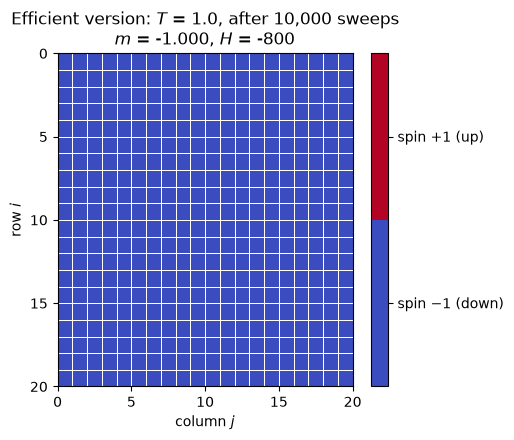

In [4]:
def metropolis_fast(S, T, sweeps, seed, J, B, kb):
    # faster version of metropolis_alg(): same algorithm, same random numbers, same results
    # flipping one spin only changes its bonds with its four neighbors, so the energy change is
    # dH = 2*S_ij*[J*(sum of the four neighbors) + B] and the whole lattice is not summed again
    rng = np.random.default_rng(seed)
    N = S.shape[0]

    # the total energy and magnetization are computed only once, then updated after each accepted flip
    E = ising_ham(S, J, B)
    M = int(np.sum(S))
    ms = [M/(N*N)]
    Es = [E]

    S = S.tolist()

    for sweep in range(sweeps):
        # random sites and random numbers for one whole sweep (N^2 attempted flips)
        rows = rng.integers(0, N, N*N).tolist()
        cols = rng.integers(0, N, N*N).tolist()
        rs = rng.random(N*N).tolist()

        for i, j, r in zip(rows, cols, rs):
            s = S[i][j]
            # sum of the four neighbors; % N and the index -1 wrap around (periodic boundary conditions)
            nb = S[(i + 1) % N][j] + S[i - 1][j] + S[i][(j + 1) % N] + S[i][j - 1]
            dH = 2*s*(J*nb + B)             # energy change if this spin is flipped

            # same acceptance rule as metropolis_alg()
            if dH <= 0 or r < math.exp(-dH/(kb*T)):
                S[i][j] = -s                # keep the flip
                E += dH                     # update the total energy
                M -= 2*s                    # update the total magnetization

        # record m and H at the end of each sweep
        ms.append(M/(N*N))
        Es.append(E)

    return np.array(S), np.array(ms), np.array(Es)


S_fast, ms_fast, Es_fast = metropolis_fast(S0, T, sweeps, 10, J, B, kb)
print(f"T = {T}: final m = {ms_fast[-1]:+.3f}, final H = {Es_fast[-1]:.0f}")

plot_spins(S_fast, f"Efficient version: $T$ = {T}, after {sweeps:,} sweeps\n$m$ = {ms_fast[-1]:+.3f}, $H$ = {Es_fast[-1]:.0f}")

# 3. Investigating Spontaneous Magnetization

The first cell shows the four random initial lattices, one per seed. `run_seeds()` then runs 2,500 sweeps of `metropolis_fast()` from each of them, and `plot_mE()` plots $m$ and $H$ against sweeps. 2,500 sweeps is $10^6$ attempted flips.

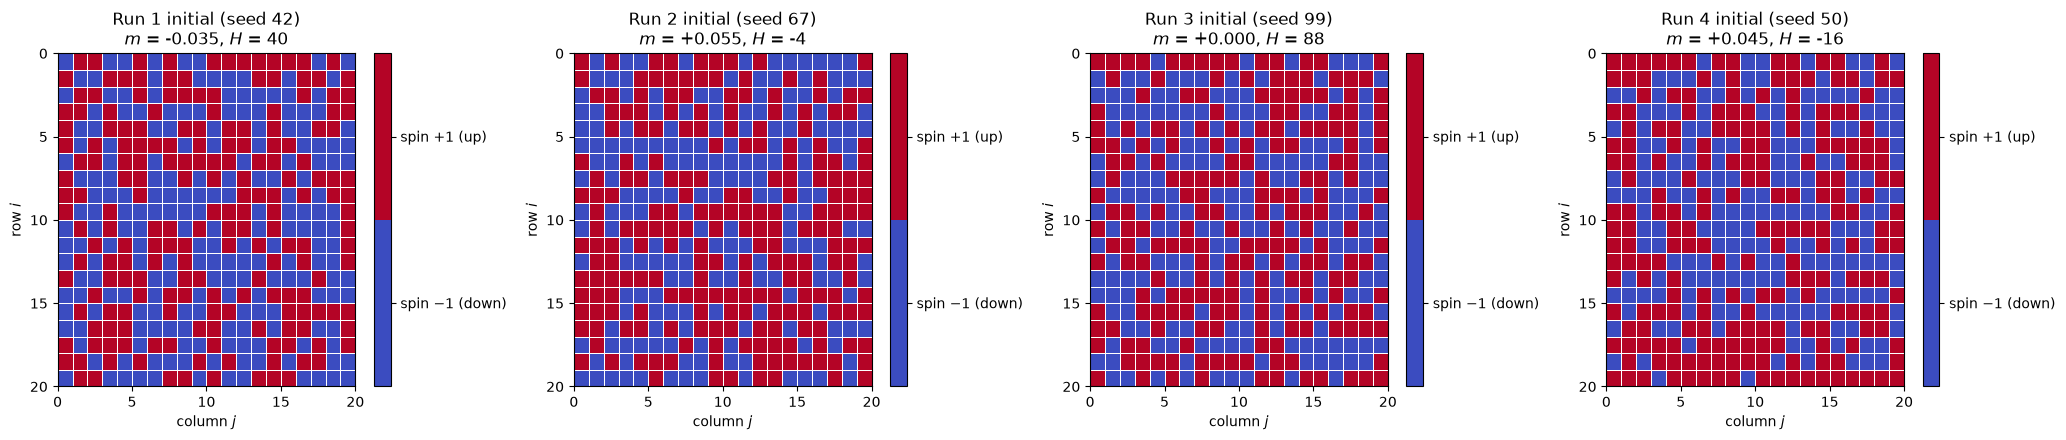

In [5]:
# Initial configurations of the four runs: one random lattice for each seed in `seeds`
S_inits, titles = [], []
for i, s in enumerate(seeds, start=1):
    S_init = lattice(N, s)
    S_inits.append(S_init)
    titles.append(f"Run {i} initial (seed {s})\n"
                  f"$m$ = {magnetization(S_init):+.3f}, $H$ = {ising_ham(S_init, J, B):.0f}")

plot_spins(S_inits, titles, "12-initial-runs.png")

Initial lattice: m = -0.035
T = 1.0, B = 0.0, lattice 42: start m = -0.035, final <m> = -0.999, final <H> = -798.7
T = 1.0, B = 0.0, lattice 67: start m = +0.055, final <m> = +0.999, final <H> = -798.5
T = 1.0, B = 0.0, lattice 99: start m = +0.000, final <m> = +0.999, final <H> = -798.6
T = 1.0, B = 0.0, lattice 50: start m = +0.045, final <m> = -0.999, final <H> = -799.2


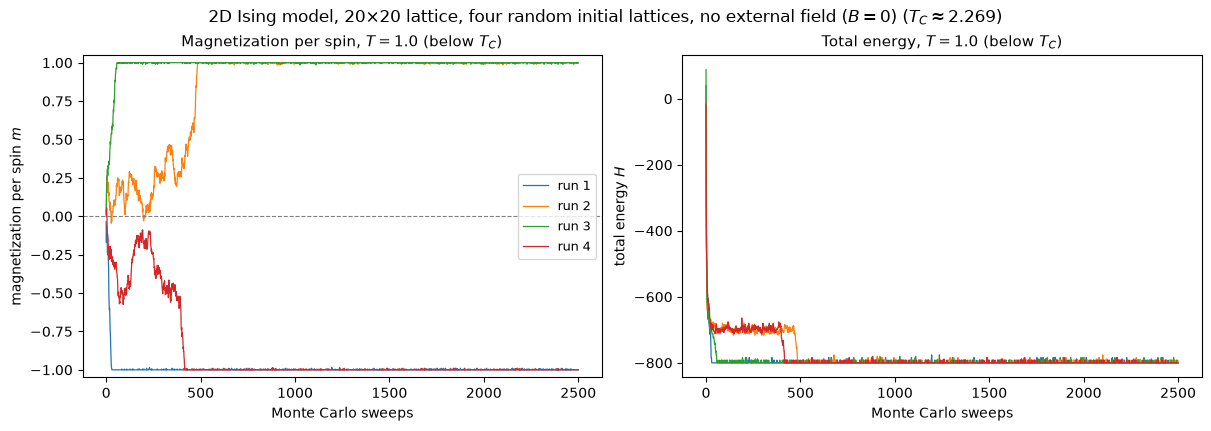

In [6]:
print(f"Initial lattice: m = {magnetization(S0):+.3f}")

def run_seeds(T, B):
    # runs one simulation for each initial lattice in `seeds` and returns their m and H histories
    runs = []
    for s in seeds:
        S_init = lattice(N, s)

        # metropolis_fast() gives the same results as metropolis_alg(); flip seed differs from lattice seed
        _, ms, Es = metropolis_fast(S_init, T, sweeps_mE, s + 100, J, B, kb)
        runs.append((ms, Es))

        print(f"T = {T}, B = {B}, lattice {s}: start m = {ms[0]:+.3f}, final <m> = {ms[-500:].mean():+.3f}, final <H> = {Es[-500:].mean():.1f}")
    return runs


def plot_mE(rows, B, fname=None):
    # magnetization per spin (left) and total energy (right) versus sweeps, one line per run
    field = "no external field ($B = 0$)" if B == 0 else f"external field $B = {B}$"
    n = len(rows)
    fig, axes = plt.subplots(n, 2, figsize=(12, 3.9*n + 0.3), layout="constrained", squeeze=False)

    for (runs, T), (ax1, ax2) in zip(rows, axes):
        side = "below" if T < Tc else "above"
        for i, (ms, Es) in enumerate(runs, start=1):
            ax1.plot(ms, lw=0.9, label=f"run {i}")
            ax2.plot(Es, lw=0.9)

        ax1.axhline(0, color="gray", ls="--", lw=0.8)
        ax1.set_ylim(-1.05, 1.05)
        ax1.set_ylabel("magnetization per spin $m$")
        ax2.set_ylabel("total energy $H$")
        ax1.set_title(f"Magnetization per spin, $T = {T}$ ({side} $T_C$)", fontsize=11)
        ax2.set_title(f"Total energy, $T = {T}$ ({side} $T_C$)", fontsize=11)

    for ax in axes[-1]:
        ax.set_xlabel("Monte Carlo sweeps")

    fig.suptitle(f"2D Ising model, {N}$\\times${N} lattice, four random initial lattices, {field} ($T_C \\approx {Tc}$)")
    axes[0, 0].legend(loc="best", fontsize=9)
    if fname is not None:
        fig.savefig(fname, dpi=150)
    plt.show()

# four different initial lattices at T = 1, no field
runs = run_seeds(T, B)
plot_mE([(runs, T)], B)

# 4. Introducing an External Magnetic Field


T = 1.0, B = 0.5, lattice 42: start m = -0.035, final <m> = +1.000, final <H> = -999.7
T = 1.0, B = 0.5, lattice 67: start m = +0.055, final <m> = +1.000, final <H> = -999.4
T = 1.0, B = 0.5, lattice 99: start m = +0.000, final <m> = +1.000, final <H> = -999.5
T = 1.0, B = 0.5, lattice 50: start m = +0.045, final <m> = +1.000, final <H> = -999.5


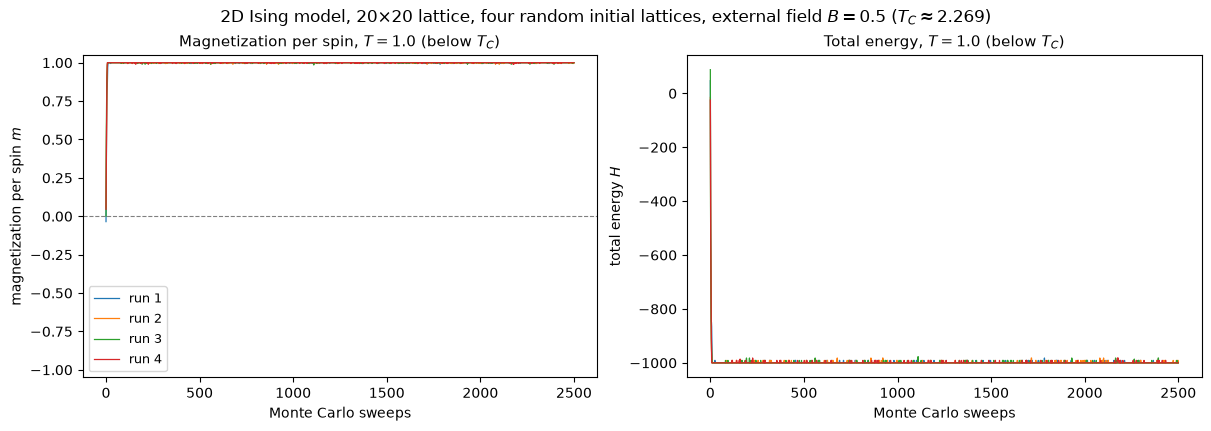

In [7]:
# same four initial lattices at T = 1, now with the external field B = 0.5
runs_B = run_seeds(T, B_field)
plot_mE([(runs_B, T)], B_field)

# 5. Critical Temperature

Sections 2 to 4 are repeated at $T=3.5$, above $T_C\approx2.269$, with the same initial lattices and seeds, so only the temperature changes.

T = 3.5: final m = -0.055, final H = -260


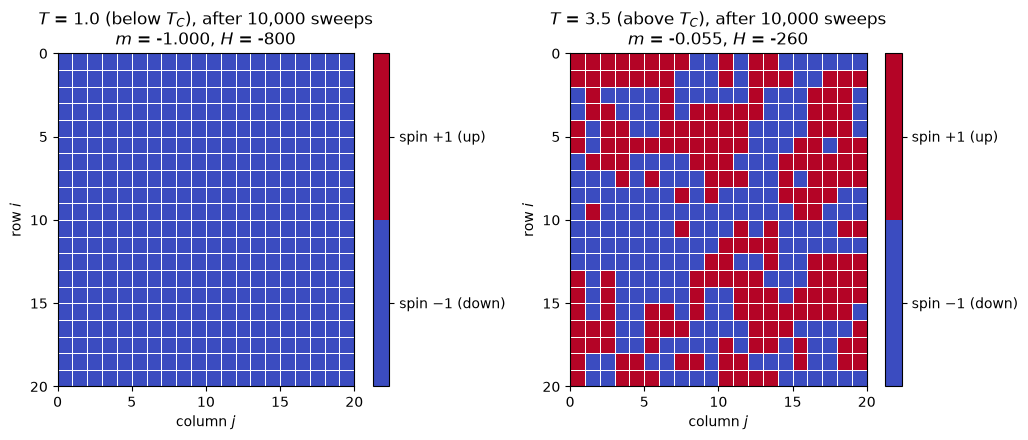

T = 3.5, B = 0.0, lattice 42: start m = -0.035, final <m> = +0.001, final <H> = -264.9
T = 3.5, B = 0.0, lattice 67: start m = +0.055, final <m> = -0.008, final <H> = -262.3
T = 3.5, B = 0.0, lattice 99: start m = +0.000, final <m> = +0.005, final <H> = -264.7
T = 3.5, B = 0.0, lattice 50: start m = +0.045, final <m> = -0.008, final <H> = -262.4


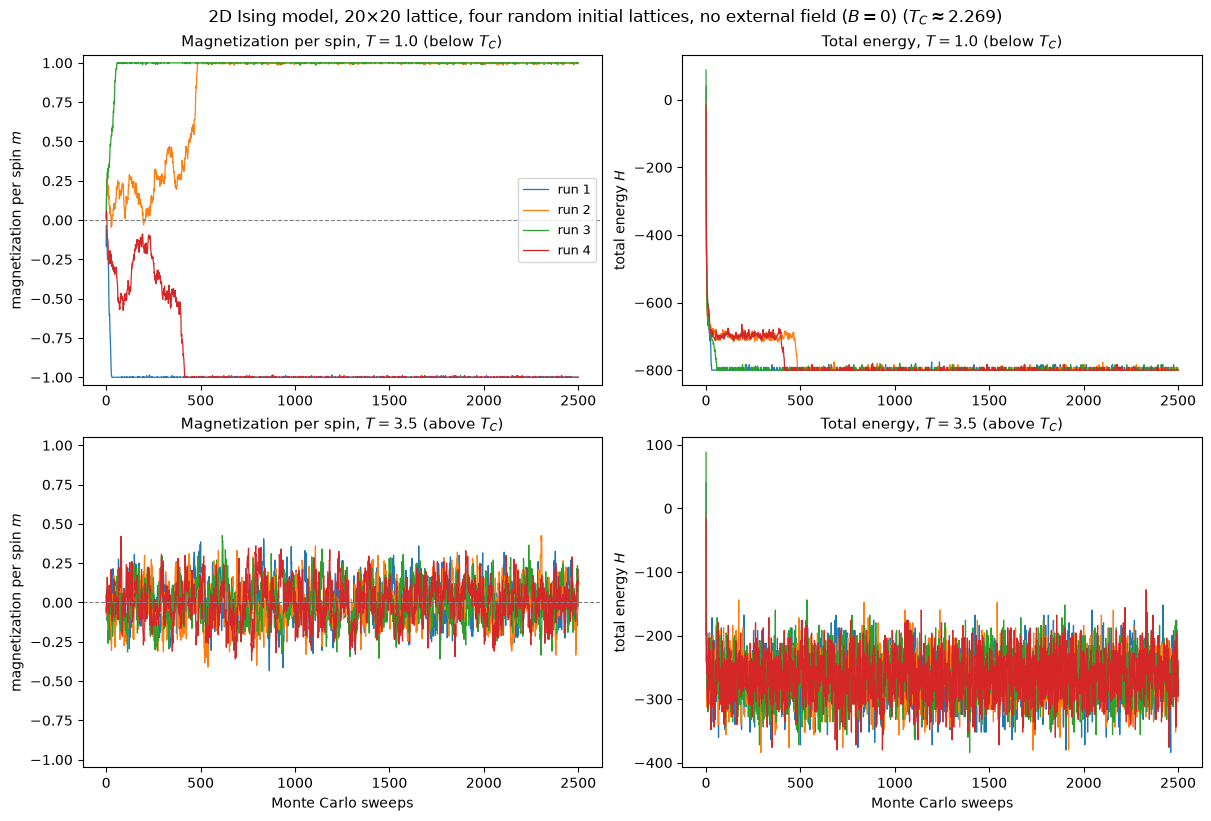

T = 3.5, B = 0.5, lattice 42: start m = -0.035, final <m> = +0.601, final <H> = -532.8
T = 3.5, B = 0.5, lattice 67: start m = +0.055, final <m> = +0.606, final <H> = -534.4
T = 3.5, B = 0.5, lattice 99: start m = +0.000, final <m> = +0.598, final <H> = -529.8
T = 3.5, B = 0.5, lattice 50: start m = +0.045, final <m> = +0.602, final <H> = -532.9


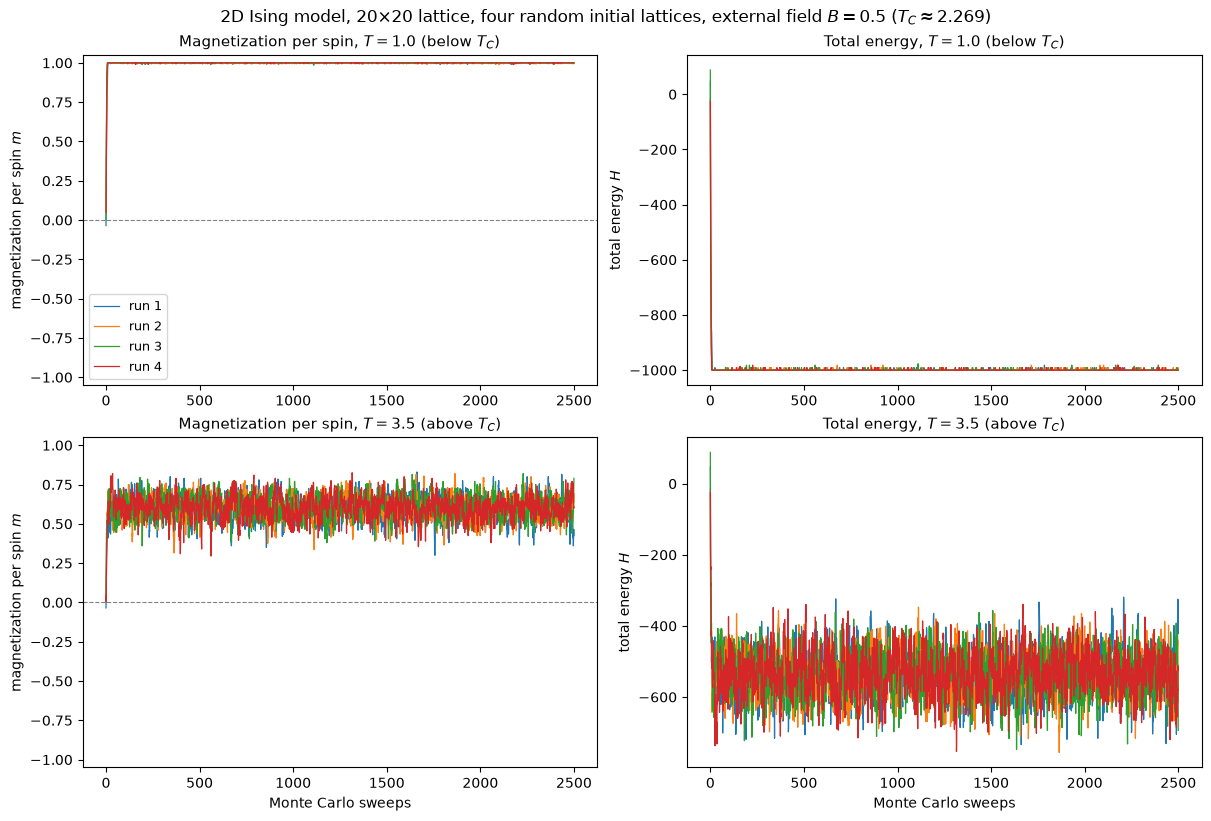

In [9]:
# Section 2 below T_C (efficient version): same initial lattice, 10,000 sweeps
# Section 2: same initial lattice, 10,000 sweeps
S_final, ms, Es = metropolis_fast(S0, T, sweeps, 10, J, B, kb)
S_final_high, ms_high, Es_high = metropolis_fast(S0, T_high, sweeps, 10, J, B, kb)
print(f"T = {T_high}: final m = {ms_high[-1]:+.3f}, final H = {Es_high[-1]:.0f}")

# final configurations below and above T_C side by side (same initial lattice)
titles = []
for S_end, T_run in zip((S_final, S_final_high), (T, T_high)):
    side = "below" if T_run < Tc else "above"
    titles.append(f"$T$ = {T_run} ({side} $T_C$), after {sweeps:,} sweeps\n m$m$ = {magnetization(S_end):+.3f}, $H$ = {ising_ham(S_end, J, B):.0f}")
plot_spins([S_final, S_final_high], titles, "12-spins.png")

# Section 3: no field; report figure with both temperatures
runs_high = run_seeds(T_high, B)
plot_mE([(runs, T), (runs_high, T_high)], B, "12-mE.png")

# Section 4: with B = 0.5; report figure with both temperatures
runs_B_high = run_seeds(T_high, B_field)
plot_mE([(runs_B, T), (runs_B_high, T_high)], B_field, "12-mE-B.png")

### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
* This code simulates the two-dimensional Ising model on a $20\times20$ periodic lattice with the Metropolis Monte Carlo algorithm to see how temperature and an external field affect the energy and magnetization. `metropolis_alg` follows the problem statement directly: each sweep draws its $N^2$ random sites and acceptance numbers at once, then flips one spin at a time, recomputes the total energy with the vectorized `ising_ham` (which uses `np.roll` for the periodic neighbors so every bond is counted once), and accepts the flip with probability $\min(1, e^{-\Delta H/k_BT})$. Because summing the whole lattice for every flip is slow, `metropolis_fast` repeats the same algorithm with the local $\Delta H$ of the four neighbors, gives the same results with far less work per flip, and is reused with $T$ and $B$ as arguments for Sections 3 to 5, where separate seeds for the lattice and for the flips keep every run reproducible while starting from different random configurations.

# Appendix

## More Rudimentary Metropolis Algorithm Implementation

`metropolis_alg()` draws the random sites and acceptance numbers for a whole sweep ($N^2$ attempted flips) at once. Each attempt flips one spin, recomputes the energy, and keeps the flip if the energy drops or if a uniform random number is below $e^{-\Delta H/k_BT}$; otherwise the spin is flipped back. $m$ and $H$ are recorded after every sweep.

T = 1.0: final m = -1.000, final H = -800


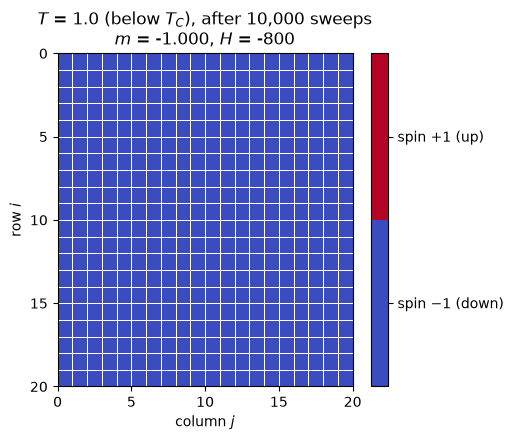

In [ ]:
def metropolis_alg(S, T, sweeps, seed, J, B, kb):
    # Metropolis Monte Carlo: starts from lattice S and runs `sweeps` sweeps at temperature T
    # returns the final lattice and the m and H histories (one value per sweep, plus the start)
    rng = np.random.default_rng(seed)
    S = S.copy()                            # keep the initial lattice unchanged
    N = S.shape[0]

    # starting energy and magnetization
    E = ising_ham(S, J, B)
    ms = [np.sum(S)/(N*N)]
    Es = [E]

    for sweep in range(sweeps):
        # random sites and random numbers for one whole sweep (N^2 attempted flips)
        rows = rng.integers(0, N, N*N)
        cols = rng.integers(0, N, N*N)
        rs = rng.random(N*N)

        for i, j, r in zip(rows, cols, rs):
            S[i, j] = -S[i, j]                  # try flipping the spin
            E_new = ising_ham(S, J, B)          # energy of the new lattice

            # accept if the energy goes down, or with probability e^(-(E_new - E)/kT) if it goes up
            if E_new <= E or r < math.exp(-(E_new - E)/(kb*T)):
                E = E_new                       # keep the flip
            else:
                S[i, j] = -S[i, j]              # reject: flip the spin back

        # record m and H at the end of each sweep
        ms.append(np.sum(S)/(N*N))
        Es.append(E)

    return S, np.array(ms), np.array(Es)


# test run: 10,000 sweeps at T = 1 (below T_C) starting from the Section 1 lattice
S_final, ms, Es = metropolis_alg(S0, T, sweeps, 10, J, B, kb)
print(f"T = {T}: final m = {ms[-1]:+.3f}, final H = {Es[-1]:.0f}")

plot_spins(S_final, f"$T$ = {T} (below $T_C$), after {sweeps:,} sweeps\n$m$ = {ms[-1]:+.3f}, $H$ = {Es[-1]:.0f}")